# 00 — Scalar variables: correlation and lag study

One number per shot for each of:

| group | variables |
|---|---|
| charge (reference) | `BCM_GUN` |
| laser power | `lab_laser_power`, `clex_laser_power` |
| magnets | `SNH_110`, `SNI_120`, `DHG0130` |
| environment | `TEMP1` … `TEMP4`, `HUMID1` … `HUMID4` |

1. **Data quality** — resolution and how often each value really changes
2. **Over the run** — every variable vs time
3. **Lag study** — `X[i + L]` vs `BCM_GUN[i]` for L = −5 … +5 (rows as recorded)
4. **Correlation study** — all pairs, after shifting each variable by its lag from step 3

**overall** r uses the raw values (includes the slow drift); **shot-to-shot** r removes a 51-shot rolling mean first.
Noise level for ~2100 shots: |r| ≲ 0.07.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

SCALARS = ["lab_laser_power", "clex_laser_power", "SNH_110", "SNI_120", "DHG0130",
           *[f"TEMP{i}" for i in range(1, 5)], *[f"HUMID{i}" for i in range(1, 5)]]
LAGS = np.arange(-5, 6)

DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])
INK, MUTED, POINT = "#2b2b29", "#8a8985", "#2a78d6"


def load(key):
    return np.concatenate([h5py.File(path, "r")[key][:] for path in files])


data = pd.DataFrame({name: load(name) for name in ["BCM_GUN", *SCALARS]})
data = data.replace([np.inf, -np.inf], np.nan)
minutes = (load("pc_time") - load("pc_time")[0]) / 60
print(f"{len(data)} shots, {data.isna().sum().sum()} non-finite values set to NaN")

2100 shots, 0 non-finite values set to NaN


## 1. Data quality

- **distinct values** / **step**: the readout resolution. Few distinct values = the shot-to-shot changes are mostly readout steps.
- **changed vs previous shot**: how often the value is updated (a repeat can be a real repeat or a stale reading).

In [2]:
def smallest_step(x):
    steps = np.diff(np.unique(x.dropna()))
    return steps[steps > 0].min() if len(steps) else np.nan


quality = pd.DataFrame({
    "mean": data.mean(),
    "std": data.std(),
    "distinct values": data.nunique(),
    "step": data.apply(smallest_step),
    "std / step": data.std() / data.apply(smallest_step),
    "changed vs previous shot": (data.diff() != 0).mean(),
})
quality.style.format({"mean": "{:.4g}", "std": "{:.3g}", "step": "{:.3g}", "std / step": "{:.1f}",
                      "changed vs previous shot": "{:.0%}"})

,mean,std,distinct values,step,std / step,changed vs previous shot
BCM_GUN,5.601,0.257,1968,4.57e-05,5627.3,100%
lab_laser_power,1.134e-05,4.03e-07,226,9.03e-09,44.6,92%
clex_laser_power,7.584e-06,3.99e-07,628,2.46e-09,162.2,94%
SNH_110,220,0.00753,9,0.00499,1.5,69%
SNI_120,330.3,0.162,36,0.0305,5.3,89%
DHG0130,0.5404,0.00135,24,0.000382,3.5,92%
TEMP1,19.72,0.0184,15,0.0122,1.5,78%
TEMP2,21.99,0.0379,22,0.0122,3.1,80%
TEMP3,21.4,0.0304,19,0.0122,2.5,81%
TEMP4,20.78,0.0312,18,0.0122,2.6,83%


## 2. Over the run

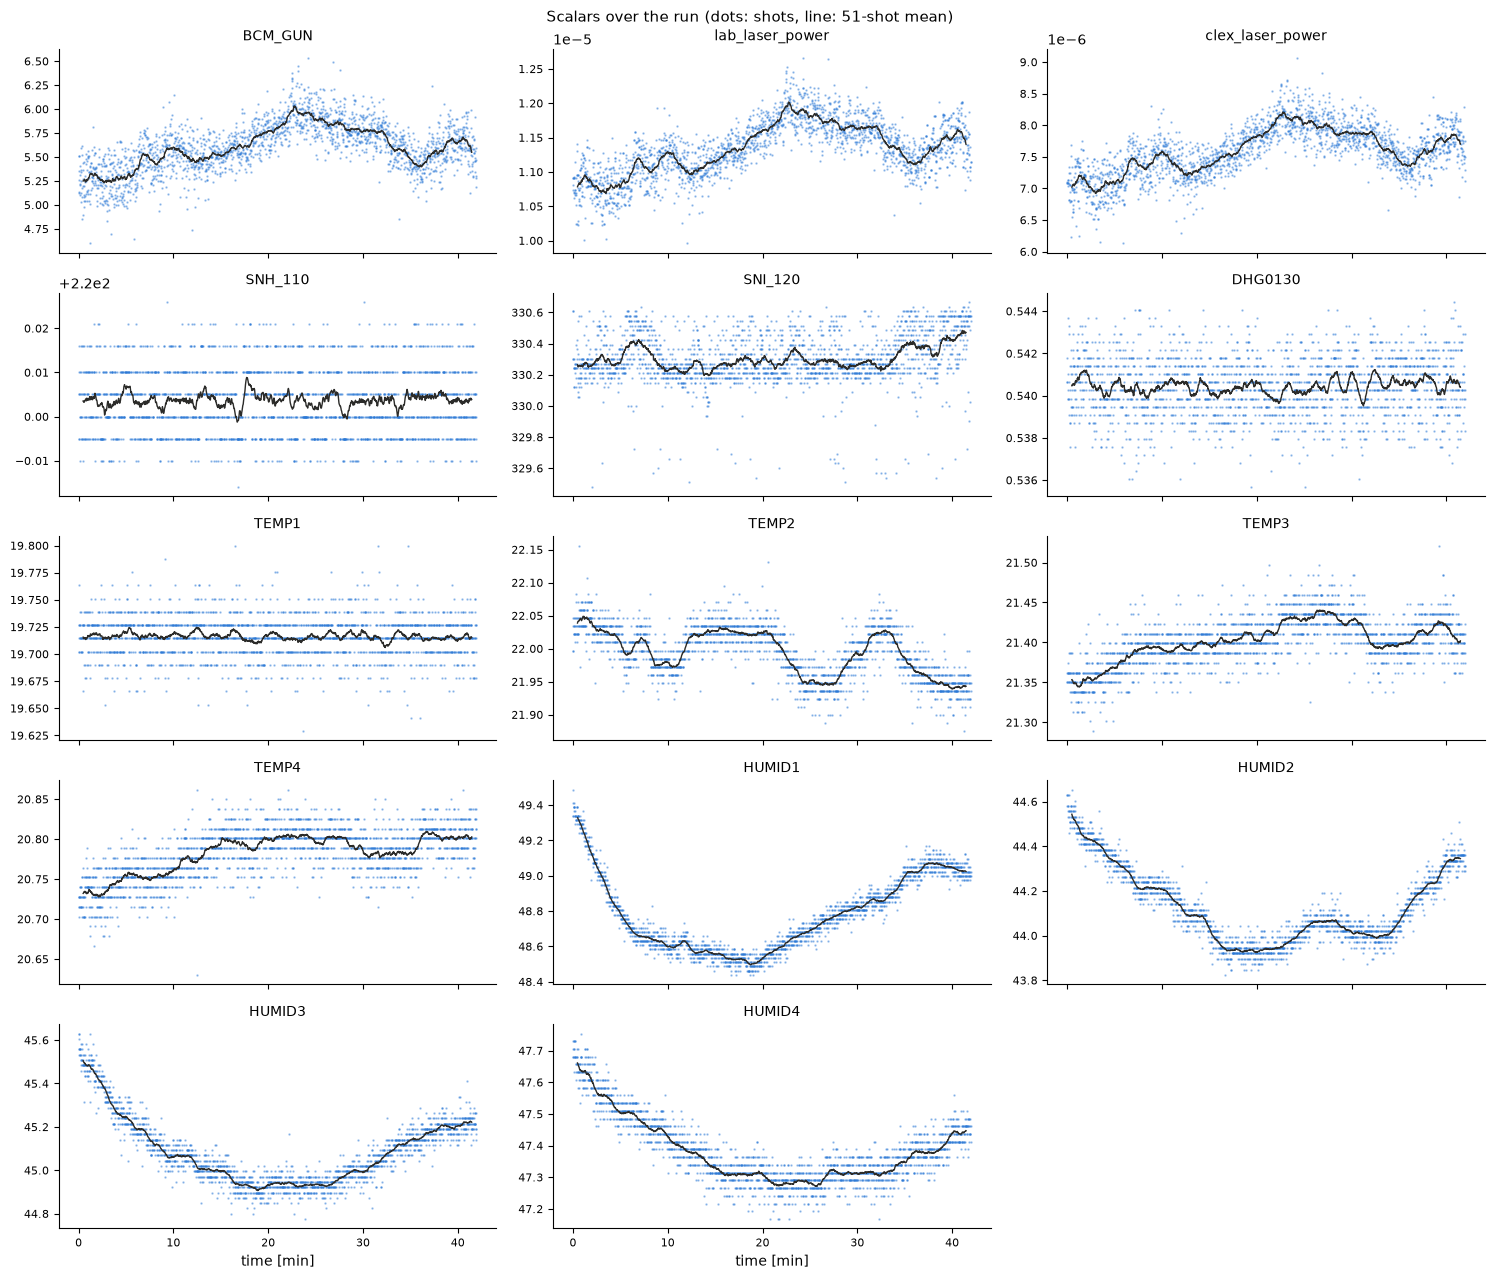

In [3]:
names = data.columns
fig, axes = plt.subplots(5, 3, figsize=(15, 13), sharex=True)
for ax, name in zip(axes.ravel(), names):
    ax.plot(minutes, data[name], ".", ms=1.5, color=POINT, alpha=0.4)
    ax.plot(minutes, data[name].rolling(51, center=True).mean(), color=INK, lw=1)
    ax.set_title(name, fontsize=10)
    ax.tick_params(labelsize=8)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
for ax in axes.ravel()[len(names):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("time [min]")
fig.suptitle("Scalars over the run (dots: shots, line: 51-shot mean)", fontsize=11)
fig.tight_layout()

## 3. Lag study against BCM_GUN

For lag *L*: `X[i + L]` vs `BCM_GUN[i]`, rows as recorded. A peak at **L = +1** means X is stored one row later than the charge.

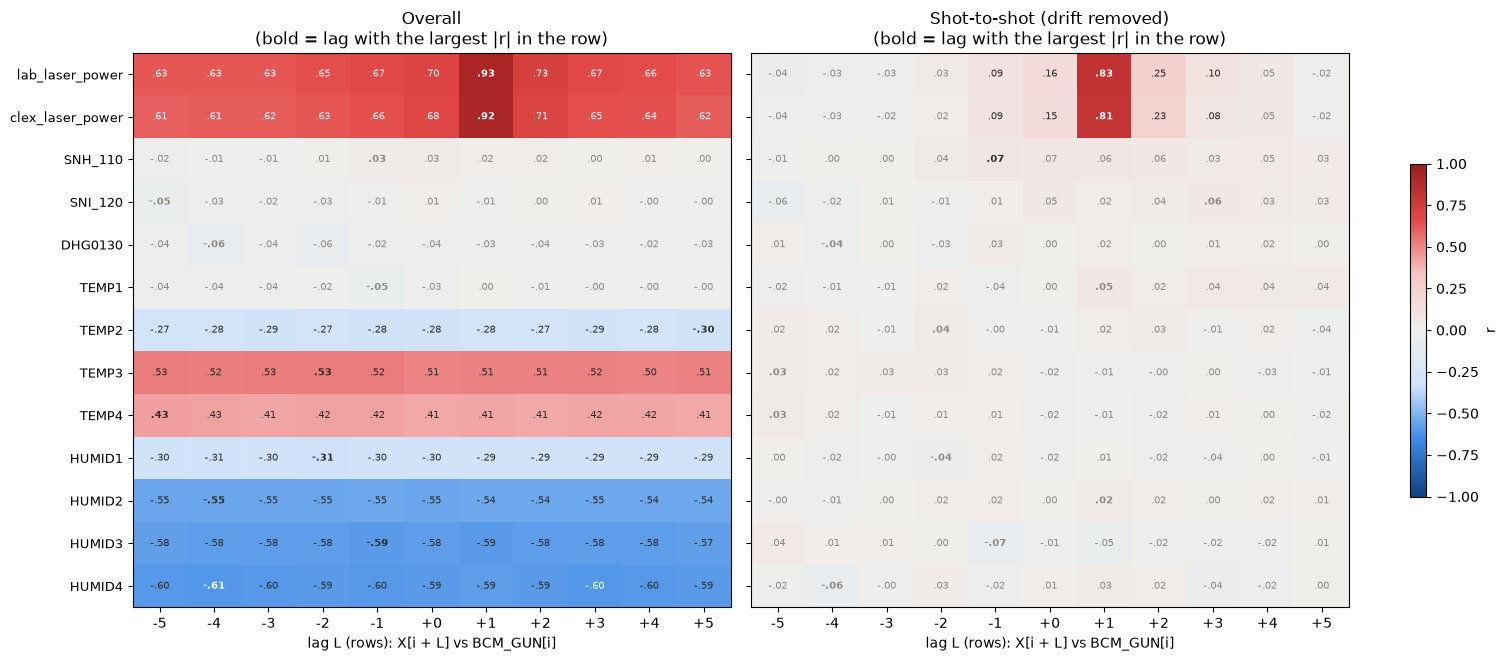

In [4]:
def detrend(x, k=51):
    return x - x.rolling(k, center=True, min_periods=1).mean()


def lag_scan(frame, ref, shot_to_shot):
    if shot_to_shot:
        frame, ref = frame.apply(detrend), detrend(ref)
    return pd.DataFrame({lag: frame.corrwith(ref.shift(lag)) for lag in LAGS})  # frame[i] vs ref[i - lag] == frame[i + lag] vs ref[i]


scan = {
    "Overall": lag_scan(data[SCALARS], data["BCM_GUN"], shot_to_shot=False),
    "Shot-to-shot (drift removed)": lag_scan(data[SCALARS], data["BCM_GUN"], shot_to_shot=True),
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), layout="constrained")
for ax, (title, table) in zip(axes, scan.items()):
    im = ax.imshow(table, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    best = table.abs().to_numpy().argmax(axis=1)
    for (i, j), r in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f"{r:.2f}".replace("0.", "."), ha="center", va="center", fontsize=7,
                color="white" if abs(r) > 0.6 else (INK if abs(r) >= 0.07 else MUTED),
                fontweight="bold" if j == best[i] else "normal")
    ax.set_xticks(range(len(LAGS)), [f"{lag:+d}" for lag in LAGS])
    ax.set_yticks(range(len(table)), table.index if ax is axes[0] else [], fontsize=9)
    ax.set(xlabel="lag L (rows): X[i + L] vs BCM_GUN[i]", title=f"{title}\n(bold = lag with the largest |r| in the row)")
fig.colorbar(im, ax=axes, shrink=0.6, label="r");

In [5]:
# We pick the best of 11 lags, so a ±3σ bar would let noise through by chance; require 5σ to apply a shift
threshold = 5 / np.sqrt(len(data))
s2s = scan["Shot-to-shot (drift removed)"]
best_lag = s2s.abs().idxmax(axis=1)
significant = s2s.abs().max(axis=1) > threshold
print(f"shift applied only if |r| at the best lag > {threshold:.3f} (5σ)")

lag_summary = pd.DataFrame({
    "best lag (shot-to-shot)": best_lag,
    "r at best lag": [s2s.loc[n, best_lag[n]] for n in SCALARS],
    "r at lag 0": s2s[0],
    "significant": significant,
})
# shift used in the correlation study: the best lag if it is significant, otherwise 0
SHIFT = best_lag.where(significant, 0)
lag_summary["shift used below"] = SHIFT
lag_summary.round(3)

shift applied only if |r| at the best lag > 0.109 (5σ)


,best lag (shot-to-shot),r at best lag,r at lag 0,significant,shift used below
lab_laser_power,1,0.826,0.163,True,1
clex_laser_power,1,0.810,0.155,True,1
SNH_110,-1,0.072,0.070,False,0
SNI_120,3,0.058,0.052,False,0
DHG0130,-4,-0.038,0.003,False,0
TEMP1,1,0.049,0.001,False,0
TEMP2,-2,0.039,-0.009,False,0
TEMP3,-5,0.030,-0.019,False,0
TEMP4,-5,0.034,-0.023,False,0
HUMID1,-2,-0.042,-0.021,False,0


## 4. Correlation study

Each variable is shifted by its lag from the table above (`X[i + shift]` is put in row *i*), then all pairs are correlated.
Only the lower triangle is shown.

2099 shots after alignment | shifts applied: {'lab_laser_power': 1, 'clex_laser_power': 1}


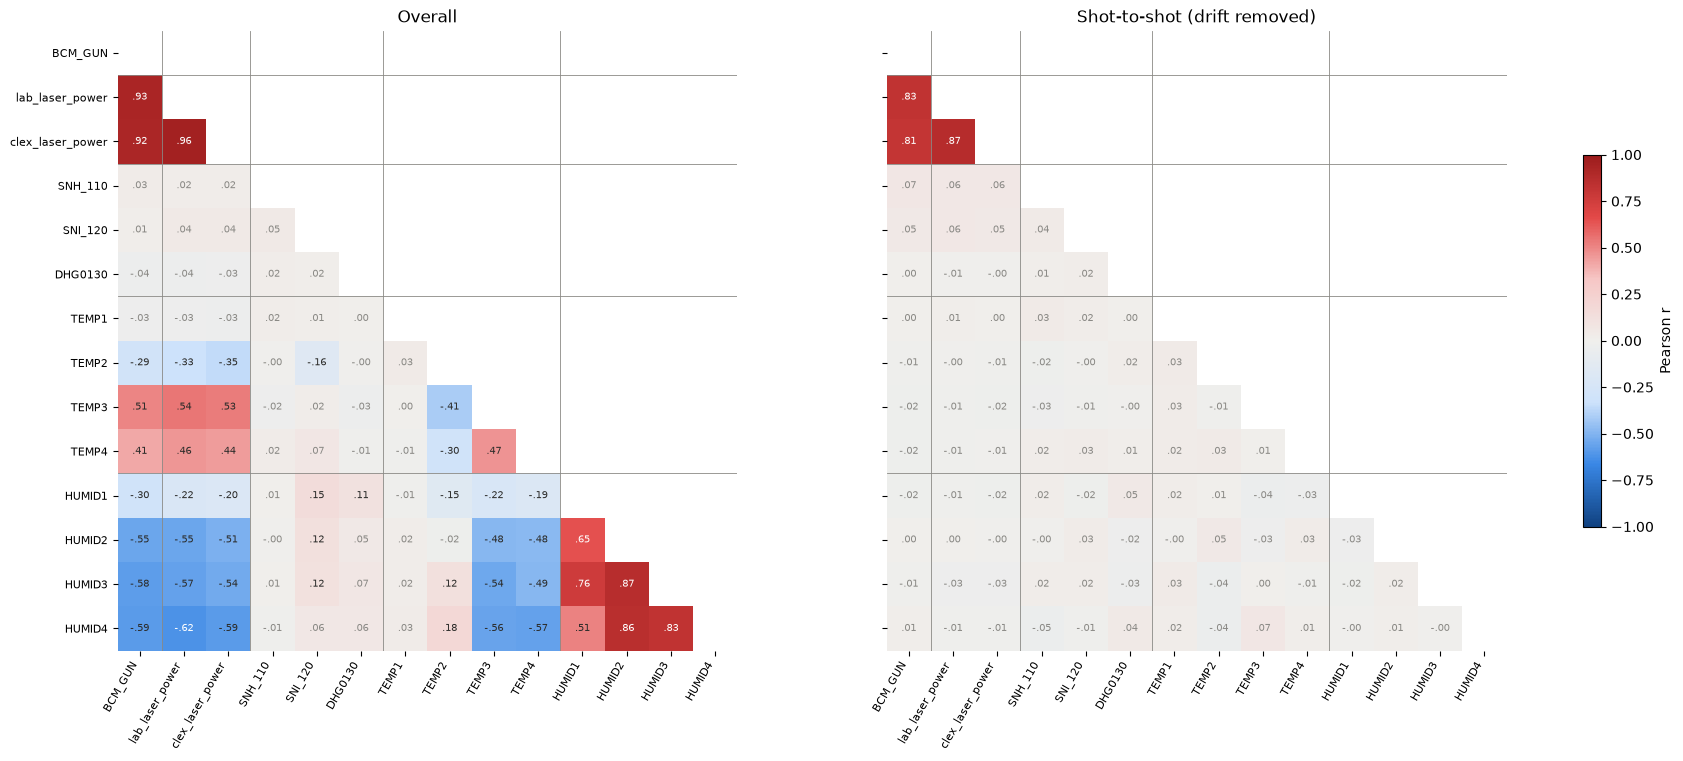

In [6]:
aligned = data.copy()
for name, s in SHIFT.items():
    aligned[name] = data[name].shift(-s)
aligned = aligned.dropna()
print(f"{len(aligned)} shots after alignment | shifts applied: {SHIFT[SHIFT != 0].to_dict() or 'none'}")

matrices = {"Overall": aligned.corr(), "Shot-to-shot (drift removed)": aligned.apply(detrend).corr()}
lower = np.tril(np.ones((len(names), len(names)), dtype=bool), k=-1)
group_edges = [names.get_loc(c) - 0.5 for c in ["lab_laser_power", "SNH_110", "TEMP1", "HUMID1"]]

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), layout="constrained")
for ax, (title, m) in zip(axes, matrices.items()):
    shown = np.where(lower, m.to_numpy(), np.nan)
    im = ax.imshow(shown, cmap=DIVERGING, vmin=-1, vmax=1)
    for (i, j), r in np.ndenumerate(shown):
        if not np.isnan(r):
            ax.text(j, i, f"{r:.2f}".replace("0.", "."), ha="center", va="center", fontsize=7,
                    color="white" if abs(r) > 0.6 else (INK if abs(r) >= 0.1 else MUTED))
    for e in group_edges:
        ax.axhline(e, color=MUTED, lw=0.6)
        ax.axvline(e, color=MUTED, lw=0.6)
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names if ax is axes[0] else [], fontsize=8)
    ax.set_title(title)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.6, label="Pearson r");

### Each scalar vs BCM_GUN (aligned)

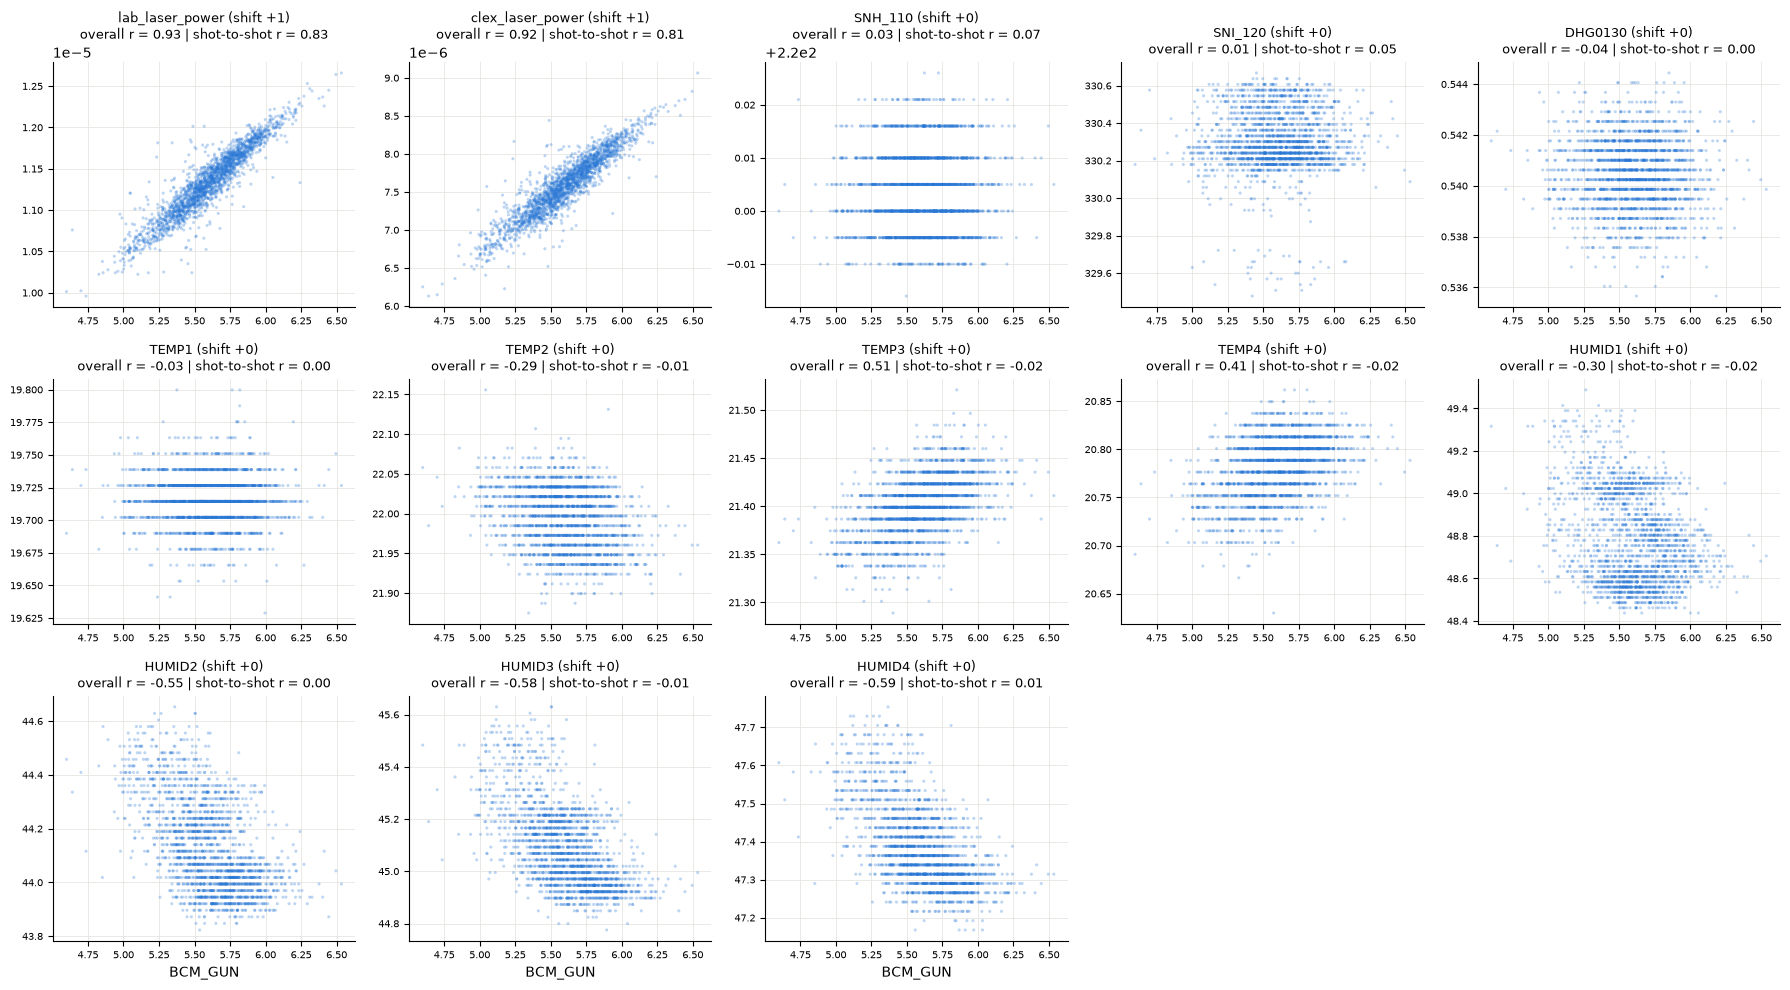

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, name in zip(axes.ravel(), SCALARS):
    ax.scatter(aligned["BCM_GUN"], aligned[name], s=5, color=POINT, alpha=0.3, edgecolors="none")
    ax.set_title(f"{name} (shift {SHIFT[name]:+d})\noverall r = {matrices['Overall'].loc[name, 'BCM_GUN']:.2f} | "
                 f"shot-to-shot r = {matrices['Shot-to-shot (drift removed)'].loc[name, 'BCM_GUN']:.2f}", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
for ax in axes.ravel()[len(SCALARS):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("BCM_GUN")
fig.tight_layout()